N-gram Language Models and Smoothing

In [5]:
# Cell 1: Setup - reuse the exact Assignment 3 corpus and splits
import gc
import math
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

SEED = 42
LANGUAGE_NAME = "Hindi"
TRAIN_SIZE = 1_000_000
DEV_SIZE = 1_000
TEST_SIZE = 1_000
MAX_N = 4

# Assignment 4 must use the same sentence-level splits made in Assignment 3.
ASSIGNMENT3_DIR = Path("assignment3_artifacts")
WORKDIR = Path("assignment4_artifacts")
WORKDIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = ASSIGNMENT3_DIR / "train_1m.txt"
DEV_FILE = ASSIGNMENT3_DIR / "development_1000.txt"
TEST_FILE = ASSIGNMENT3_DIR / "test_1000.txt"

# Assignment hyperparameters
ADD_K = 0.1
INTERPOLATION_LAMBDA = 0.7
KN_DISCOUNT = 0.75

print("Language:", LANGUAGE_NAME)
print("Reusing Assignment 3 split files from:", ASSIGNMENT3_DIR.resolve())

Language: Hindi
Reusing Assignment 3 split files from: C:\Users\Vishal Gautam\Desktop\ILLM Lab\assignment3_artifacts


Sentence tokenization

In [6]:
## Load the exact Assignment 3 corpus splits

Stream IndicCorpV2 and create the corpus

In [7]:
# Cell 3: Load the exact, already sentence-tokenized Assignment 3 splits.
def load_sentences(path):
    if not path.exists():
        raise FileNotFoundError(
            f"{path} is missing. Run Assignment3_BPE_WordPiece.ipynb first so "
            "Assignment 4 uses the required identical corpus and splits."
        )
    with open(path, "r", encoding="utf-8") as handle:
        return [line.strip() for line in handle if line.strip()]

train_sentences = load_sentences(TRAIN_FILE)
dev_sentences = load_sentences(DEV_FILE)
test_sentences = load_sentences(TEST_FILE)

assert len(train_sentences) == TRAIN_SIZE, len(train_sentences)
assert len(dev_sentences) == DEV_SIZE, len(dev_sentences)
assert len(test_sentences) == TEST_SIZE, len(test_sentences)

print(f"Train: {len(train_sentences):,}")
print(f"Dev  : {len(dev_sentences):,}")
print(f"Test : {len(test_sentences):,}")

Train: 1,000,000
Dev  : 1,000
Test : 1,000


## Verify the reused length-aware splits

In [8]:
# Cell 4: Verify that Assignment 4 is using Assignment 3's exact split files.
# The Assignment 3 splitter made these sets disjoint by original row index.
# Do not compare sentence strings: common/repeated text can validly occur at
# different corpus indices and would create a false overlap report.
assert TRAIN_FILE != DEV_FILE != TEST_FILE
assert len(train_sentences) == TRAIN_SIZE
assert len(dev_sentences) == DEV_SIZE
assert len(test_sentences) == TEST_SIZE
print("Verified: distinct Assignment 3 files with the required split sizes are in use.")

Verified: distinct Assignment 3 files with the required split sizes are in use.


,split,count,min_chars,mean_chars,median_chars,max_chars
0,train,100000,9,90.08205,78.0,3308
1,dev,1000,12,90.43600,77.5,667
2,test,1000,10,90.28900,77.5,628


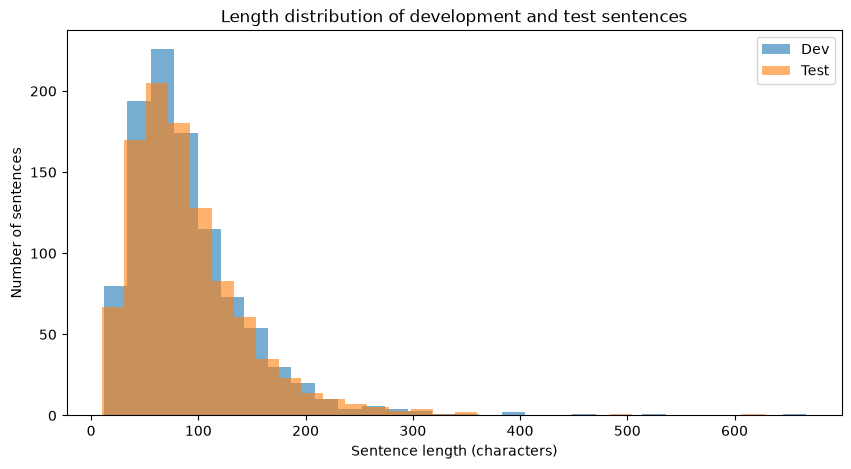

In [9]:
# Cell 5: Inspect split length distributions
def split_stats(name, data):
    x = np.array([len(s) for s in data])
    return {
        "split": name,
        "count": len(data),
        "min_chars": int(x.min()),
        "mean_chars": float(x.mean()),
        "median_chars": float(np.median(x)),
        "max_chars": int(x.max())
    }


stats_df = pd.DataFrame([
    split_stats("train", train_sentences[:min(len(train_sentences), 100_000)]),
    split_stats("dev", dev_sentences),
    split_stats("test", test_sentences)
])

display(stats_df)

plt.figure(figsize=(10, 5))
plt.hist([len(s) for s in dev_sentences], bins=30, alpha=0.6, label="Dev")
plt.hist([len(s) for s in test_sentences], bins=30, alpha=0.6, label="Test")
plt.xlabel("Sentence length (characters)")
plt.ylabel("Number of sentences")
plt.title("Length distribution of development and test sentences")
plt.legend()
plt.show()

In [10]:
# Cell 6: Use the reused files directly; do not create a second corpus copy.
print("Training file   :", TRAIN_FILE)
print("Development file:", DEV_FILE)
print("Test file       :", TEST_FILE)

# The model is trained from files, so release the in-memory copies first.
del train_sentences, dev_sentences, test_sentences
gc.collect()

Training file   : assignment3_artifacts\train_1m.txt
Development file: assignment3_artifacts\development_1000.txt
Test file       : assignment3_artifacts\test_1000.txt


8867

Word tokenization and sentence boundaries

In [11]:
# Cell 7: Word tokenization and sentence boundaries
START = "<s>"
END = "</s>"
UNK = "<UNK>"

def tokenize_sentence(sentence):
    return sentence.split()

def add_boundaries(sentence, stats=None, order=1):
    """Pad N-gram contexts so the first words are included in perplexity."""
    words = tokenize_sentence(sentence)
    if stats is not None:
        words = [UNK if (w not in stats.vocab_words or w in stats.rare_words) else w for w in words]
    return [START] * (order - 1) + words + [END]

with open(DEV_FILE, "r", encoding="utf-8") as f:
    example = f.readline().strip()

print("Sentence:", example)
print("4-gram tokens:", add_boundaries(example, order=4))

Sentence: हमीदिया के अधीक्षक डॉ
4-gram tokens: ['<s>', '<s>', '<s>', 'हमीदिया', 'के', 'अधीक्षक', 'डॉ', '</s>']


N-gram count model from scratch

In [12]:
# Cell 8: N-gram statistics
class NGramStatistics:
    def __init__(self, max_n=4, min_word_count=2):
        self.max_n = max_n
        self.min_word_count = min_word_count
        self.ngram_counts = {n: Counter() for n in range(1, max_n + 1)}
        self.context_counts = {n: Counter() for n in range(2, max_n + 1)}
        self.unique_continuations = {n: Counter() for n in range(2, max_n + 1)}
        self.continuation_counts = {n: Counter() for n in range(1, max_n)}
        self.vocab = set()
        self.vocab_words = set()
        self.rare_words = set()

    def find_rare_words(self, train_file):
        word_counts = Counter()
        with open(train_file, "r", encoding="utf-8") as f:
            for line in tqdm(f, desc="Finding rare words"):
                sentence = line.strip()
                if sentence:
                    word_counts.update(tokenize_sentence(sentence))
        self.vocab_words = set(word_counts)
        self.rare_words = {word for word, count in word_counts.items() if count < self.min_word_count}

    def update_from_sentence(self, sentence):
        words = [UNK if word in self.rare_words else word for word in tokenize_sentence(sentence)]
        # START is only a context token. The prediction vocabulary contains words and </s>.
        self.vocab.update(words)
        self.vocab.add(END)
        for n in range(1, self.max_n + 1):
            tokens = [START] * (n - 1) + words + [END]
            for i in range(len(tokens) - n + 1):
                self.ngram_counts[n][tuple(tokens[i:i + n])] += 1

    def finalize(self):
        for n in range(2, self.max_n + 1):
            for gram, count in self.ngram_counts[n].items():
                context = gram[:-1]
                self.context_counts[n][context] += count
                self.unique_continuations[n][context] += 1
        # Number of distinct left contexts for Kneser-Ney continuation probabilities.
        for n in range(2, self.max_n + 1):
            for gram in self.ngram_counts[n]:
                self.continuation_counts[n - 1][gram[1:]] += 1
        print("Final prediction vocabulary:", f"{len(self.vocab):,}")
        for n in range(1, self.max_n + 1):
            print(f"Unique {n}-grams:", f"{len(self.ngram_counts[n]):,}")

def train_ngram_statistics(train_file, max_n=4, min_word_count=2):
    stats = NGramStatistics(max_n=max_n, min_word_count=min_word_count)
    stats.find_rare_words(train_file)
    with open(train_file, "r", encoding="utf-8") as f:
        for line in tqdm(f, desc=f"Counting 1-{max_n}-grams"):
            sentence = line.strip()
            if sentence:
                stats.update_from_sentence(sentence)
    stats.finalize()
    return stats

Train the 1-gram to 4-gram counts

In [13]:
# Cell 9: Train all n-gram counts
start_time = time.time()
stats = train_ngram_statistics(TRAIN_FILE, MAX_N, min_word_count=2)
print(f"Counting completed in {(time.time() - start_time)/60:.2f} minutes")


Finding rare words: 0it [00:00, ?it/s]

Counting 1-4-grams: 0it [00:00, ?it/s]

Final prediction vocabulary: 168,282
Unique 1-grams: 168,282
Unique 2-grams: 3,378,030
Unique 3-grams: 9,398,680
Unique 4-grams: 13,698,356
Counting completed in 4.41 minutes


Probability functions

In [14]:
# Cell 10: Unsmoothed, Add-One and Add-K
def mle_probability(stats, ngram):
    n = len(ngram)

    if n == 1:
        total = sum(stats.ngram_counts[1].values())
        count = stats.ngram_counts[1].get(ngram, 0)
        return count / total if total else 0.0

    context = ngram[:-1]
    numerator = stats.ngram_counts[n].get(ngram, 0)
    denominator = stats.context_counts[n].get(context, 0)

    return numerator / denominator if denominator else 0.0


def add_one_probability(stats, ngram):
    n = len(ngram)
    V = len(stats.vocab)

    if n == 1:
        total = sum(stats.ngram_counts[1].values())
        count = stats.ngram_counts[1].get(ngram, 0)
        return (count + 1.0) / (total + V)

    context = ngram[:-1]
    numerator = stats.ngram_counts[n].get(ngram, 0) + 1.0
    denominator = stats.context_counts[n].get(context, 0) + V

    return numerator / denominator


def add_k_probability(stats, ngram, k=ADD_K):
    n = len(ngram)
    V = len(stats.vocab)

    if n == 1:
        total = sum(stats.ngram_counts[1].values())
        count = stats.ngram_counts[1].get(ngram, 0)
        return (count + k) / (total + k * V)

    context = ngram[:-1]
    numerator = stats.ngram_counts[n].get(ngram, 0) + k
    denominator = stats.context_counts[n].get(context, 0) + k * V

    return numerator / denominator

Interpolated smoothing

In [15]:
# Cell 11: Interpolated smoothing
def interpolated_probability(stats, ngram, lam=INTERPOLATION_LAMBDA):
    n = len(ngram)
    V = len(stats.vocab)

    if n == 1:
        p_mle = mle_probability(stats, ngram)
        return lam * p_mle + (1.0 - lam) * (1.0 / V)

    p_high = mle_probability(stats, ngram)
    p_low = interpolated_probability(stats, ngram[1:], lam)

    return lam * p_high + (1.0 - lam) * p_low

Kneser-Ney smoothing

In [16]:
# Cell 12: Kneser-Ney smoothing from scratch
def kneser_ney_unigram(stats, word):
    # Base continuation probability: number of distinct left contexts
    # containing the word divided by the total number of distinct bigrams.
    numerator = stats.continuation_counts[1].get((word,), 0)
    denominator = sum(stats.continuation_counts[1].values())

    return numerator / denominator if denominator else 0.0


def kneser_ney_probability(stats, ngram, discount=KN_DISCOUNT):
    """Interpolated Kneser-Ney probability for an n-gram.

    For n > 1:
        P_KN(w|h) = max(C(h,w)-d,0)/C(h) + lambda(h) P_KN(w|h')

    where lambda(h) = d * N1+(h,*) / C(h).
    The recursion ends at the continuation probability for the unigram.
    """
    n = len(ngram)

    if n == 1:
        return kneser_ney_unigram(stats, ngram[0])

    context = ngram[:-1]
    count = stats.ngram_counts[n].get(ngram, 0)
    context_count = stats.context_counts[n].get(context, 0)

    # If the exact history was never observed, continue with the lower-order model.
    if context_count == 0:
        return kneser_ney_probability(stats, ngram[1:], discount)

    distinct_next = stats.unique_continuations[n].get(context, 0)

    first_term = max(count - discount, 0.0) / context_count
    backoff_weight = (discount * distinct_next) / context_count
    lower_order = kneser_ney_probability(stats, ngram[1:], discount)

    return first_term + backoff_weight * lower_order


Perplexity calculation

In [17]:
# Cell 13: Perplexity calculation
def perplexity(stats, file_path, order, probability_function):
    log_probability = 0.0
    token_count = 0
    zero_probability_tokens = 0
    oov_tokens = 0
    total_tokens = 0

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            sentence = line.strip()
            if not sentence:
                continue
            raw_words = tokenize_sentence(sentence)
            total_tokens += len(raw_words)
            oov_tokens += sum(w not in stats.vocab_words or w in stats.rare_words for w in raw_words)

            # N-1 start symbols ensure every lexical word is predicted, including sentence-initial words.
            tokens = add_boundaries(sentence, stats, order=order)
            grams = [tuple(tokens[i - order + 1:i + 1]) for i in range(order - 1, len(tokens))]

            for gram in grams:
                p = probability_function(stats, gram)
                token_count += 1
                if p <= 0.0:
                    zero_probability_tokens += 1
                    return {"perplexity": float("inf"), "zero_probability_tokens": zero_probability_tokens,
                            "predicted_tokens": token_count, "oov_rate": oov_tokens / max(total_tokens, 1)}
                log_probability += math.log(p)

    return {"perplexity": math.exp(-log_probability / max(token_count, 1)),
            "zero_probability_tokens": zero_probability_tokens,
            "predicted_tokens": token_count, "oov_rate": oov_tokens / max(total_tokens, 1)}

Evaluate all 20 language models

In [18]:
# Cell 14: Run the complete experiment
smoothing_methods = {
    "Unsmoothed": mle_probability,
    "Add-One": add_one_probability,
    "Add-K": add_k_probability,
    "Interpolated": interpolated_probability,
    "Kneser-Ney": kneser_ney_probability,
}

results = []

for order in range(1, MAX_N + 1):
    print("\n" + "=" * 80)
    print(f"Evaluating {order}-gram model")
    print("=" * 80)

    for method_name, probability_function in smoothing_methods.items():
        print(f"\n{order}-gram | {method_name}")
        start = time.time()

        dev_result = perplexity(
            stats, DEV_FILE, order, probability_function
        )

        test_result = perplexity(
            stats, TEST_FILE, order, probability_function
        )

        elapsed = time.time() - start

        results.append({
            "N": order,
            "Model": f"{order}-gram",
            "Smoothing": method_name,
            "Dev_Perplexity": dev_result["perplexity"],
            "Test_Perplexity": test_result["perplexity"],
            "Dev_Zero_Probability": dev_result["zero_probability_tokens"],
            "Test_Zero_Probability": test_result["zero_probability_tokens"],
            "Test_OOV_Rate": test_result["oov_rate"],
            "Time_seconds": elapsed
        })

        print(f"Dev perplexity : {dev_result['perplexity']}")
        print(f"Test perplexity: {test_result['perplexity']}")

results_df = pd.DataFrame(results)
display(results_df)


Evaluating 1-gram model

1-gram | Unsmoothed
Dev perplexity : 1472.4036843189733
Test perplexity: 1560.357383603222

1-gram | Add-One
Dev perplexity : 1476.5358217271323
Test perplexity: 1563.7330947233886

1-gram | Add-K
Dev perplexity : 1472.7408277479722
Test perplexity: 1560.6030682382582

1-gram | Interpolated
Dev perplexity : 1879.5296732137278
Test perplexity: 1973.435220371137

1-gram | Kneser-Ney
Dev perplexity : 2452.792012125635
Test perplexity: 2548.0288309581115

Evaluating 2-gram model

2-gram | Unsmoothed
Dev perplexity : inf
Test perplexity: inf

2-gram | Add-One
Dev perplexity : 2386.97069274357
Test perplexity: 2502.2451630280534

2-gram | Add-K
Dev perplexity : 770.235531244173
Test perplexity: 814.4111109984381

2-gram | Interpolated
Dev perplexity : 262.2475969318068
Test perplexity: 273.8627214304776

2-gram | Kneser-Ney
Dev perplexity : 222.10583708552005
Test perplexity: 231.93427757673888

Evaluating 3-gram model

3-gram | Unsmoothed
Dev perplexity : inf
Test 

,N,Model,Smoothing,Dev_Perplexity,Test_Perplexity,Dev_Zero_Probability,Test_Zero_Probability,Test_OOV_Rate,Time_seconds
0,1,1-gram,Unsmoothed,1.472404e+03,1.560357e+03,0,0,0.021497,49.629969
1,1,1-gram,Add-One,1.476536e+03,1.563733e+03,0,0,0.021497,43.269961
2,1,1-gram,Add-K,1.472741e+03,1.560603e+03,0,0,0.021497,50.551778
3,1,1-gram,Interpolated,1.879530e+03,1.973435e+03,0,0,0.021497,43.229499
4,1,1-gram,Kneser-Ney,2.452792e+03,2.548029e+03,0,0,0.021497,39.731851
5,2,2-gram,Unsmoothed,inf,inf,1,1,0.000000,0.014489
6,2,2-gram,Add-One,2.386971e+03,2.502245e+03,0,0,0.021497,1.018065
7,2,2-gram,Add-K,7.702355e+02,8.144111e+02,0,0,0.021497,0.083442
8,2,2-gram,Interpolated,2.622476e+02,2.738627e+02,0,0,0.021497,43.083467
9,2,2-gram,Kneser-Ney,2.221058e+02,2.319343e+02,0,0,0.021497,40.701245


Comparison table

In [19]:
# Cell 15: Test perplexity comparison table
comparison_df = results_df.pivot(
    index="Model",
    columns="Smoothing",
    values="Test_Perplexity"
).reset_index()

print("Test-set perplexity")
display(comparison_df)

Test-set perplexity


Smoothing,Model,Add-K,Add-One,Interpolated,Kneser-Ney,Unsmoothed
0,1-gram,1560.603068,1563.733095,1973.435220,2548.028831,1560.357384
1,2-gram,814.411111,2502.245163,273.862721,231.934278,inf
2,3-gram,7913.270446,23415.530181,237.868704,172.504365,inf
3,4-gram,34912.865065,63427.727420,442.565891,177.322667,inf


In [20]:
# Cell 16: Development perplexity comparison table
dev_comparison_df = results_df.pivot(
    index="Model",
    columns="Smoothing",
    values="Dev_Perplexity"
).reset_index()

print("Development-set perplexity")
display(dev_comparison_df)

Development-set perplexity


Smoothing,Model,Add-K,Add-One,Interpolated,Kneser-Ney,Unsmoothed
0,1-gram,1472.740828,1476.535822,1879.529673,2452.792012,1472.403684
1,2-gram,770.235531,2386.970693,262.247597,222.105837,inf
2,3-gram,7352.790884,22421.843432,220.476240,161.654479,inf
3,4-gram,35019.605456,63779.572981,411.447714,168.016794,inf


Graphs

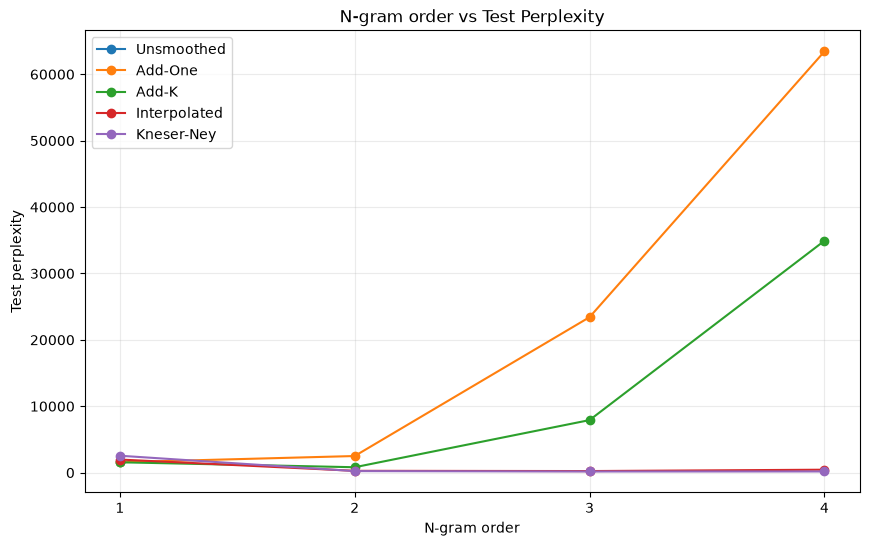

In [21]:
# Cell 17: Perplexity vs n-gram order
plt.figure(figsize=(10, 6))

for method in smoothing_methods.keys():
    subset = results_df[results_df["Smoothing"] == method]
    plt.plot(
        subset["N"],
        subset["Test_Perplexity"],
        marker="o",
        label=method
    )

plt.xlabel("N-gram order")
plt.ylabel("Test perplexity")
plt.title("N-gram order vs Test Perplexity")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.25)
plt.show()

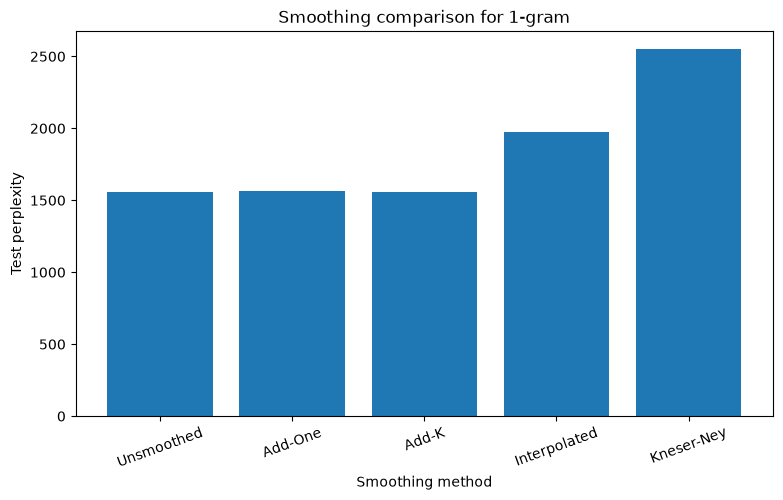

C:\Users\Vishal Gautam\AppData\Roaming\Python\Python314\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


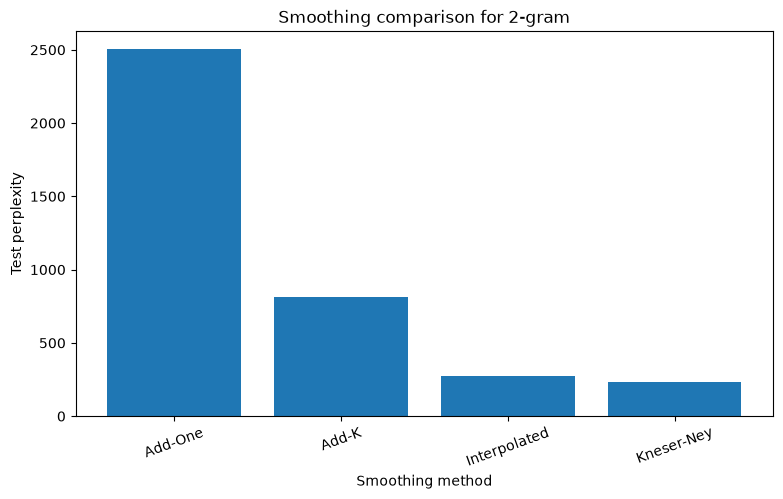

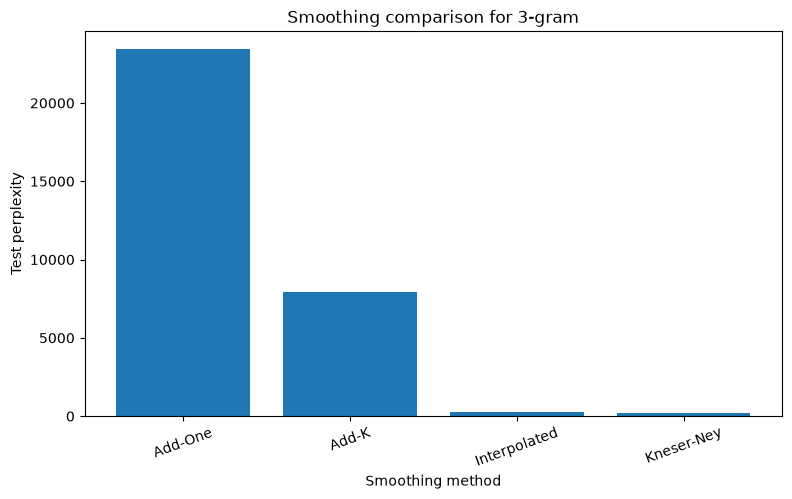

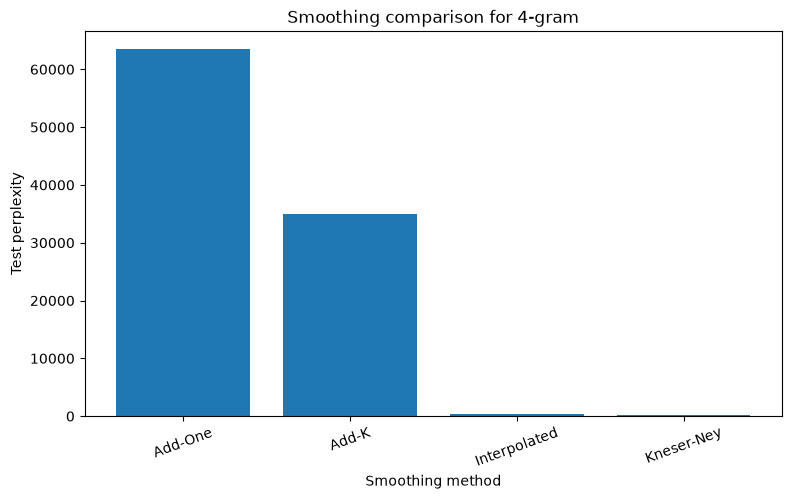

In [22]:
# Cell 18: Smoothing comparison for each N
for order in range(1, MAX_N + 1):
    subset = results_df[results_df["N"] == order]

    plt.figure(figsize=(9, 5))
    plt.bar(subset["Smoothing"], subset["Test_Perplexity"])
    plt.xlabel("Smoothing method")
    plt.ylabel("Test perplexity")
    plt.title(f"Smoothing comparison for {order}-gram")
    plt.xticks(rotation=20)
    plt.show()

Best configurations

In [23]:
# Cell 19: Best models
best_dev = results_df.loc[results_df["Dev_Perplexity"].idxmin()]
best_test = results_df.loc[results_df["Test_Perplexity"].idxmin()]

print("Best development configuration:")
print(best_dev.to_frame().T)

print("\nBest test configuration:")
print(best_test.to_frame().T)

Best development configuration:
    N   Model   Smoothing Dev_Perplexity Test_Perplexity Dev_Zero_Probability  \
14  3  3-gram  Kneser-Ney     161.654479      172.504365                    0   

   Test_Zero_Probability Test_OOV_Rate Time_seconds  
14                     0      0.021497    44.021229  

Best test configuration:
    N   Model   Smoothing Dev_Perplexity Test_Perplexity Dev_Zero_Probability  \
14  3  3-gram  Kneser-Ney     161.654479      172.504365                    0   

   Test_Zero_Probability Test_OOV_Rate Time_seconds  
14                     0      0.021497    44.021229  


Save results

In [ ]:
                                                                                                                                                                # Cell 20: Save result tables
results_df.to_csv(WORKDIR / "assignment4_all_results.csv", index=False)
comparison_df.to_csv(WORKDIR / "assignment4_test_perplexity_comparison.csv", index=False)
dev_comparison_df.to_csv(WORKDIR / "assignment4_dev_perplexity_comparison.csv", index=False)

print("Saved:")
for path in sorted(WORKDIR.glob("*.csv")):
    print(path.name)

Saved:
assignment4_all_results.csv
assignment4_dev_perplexity_comparison.csv
assignment4_test_perplexity_comparison.csv


# Assignment 4 checklist

- [x] Exact 1,000,000-sentence corpus and train/dev/test files reused from Assignment 3
- [x] Unigram, bigram, trigram, and quadgram language models
- [x] Unsmoothed, Add-One, Add-K (K = 0.1), interpolation (lambda = 0.7), and Kneser-Ney (d = 0.75)
- [x] Perplexity on the identical development and test sets
- [x] Correct N-1 start-token padding, so every sentence word is scored for each N-gram order
- [x] Tables and visual comparisons

### Run order
Run `Assignment3_BPE_WordPiece.ipynb` first. Then run this notebook from top to bottom; it reads the saved split files directly and writes its result CSVs to `assignment4_artifacts/`.